1. Exploratory Data Analysis (EDA)
2. Overview of the Dataset
3. Target Variable Distribution
4. Missing Value Analysis
5. Numerical Feature Analysis
6. Categorical Feature Analysis
7. Defaulter vs Non-Defaulter Analysis
8. Correlation Analysis
9. Key Business Insights

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv(r"D:\DataMites_documents\1st Cpaston\PRCP-1006-HomeLoanDef\Data\application_train.csv")

In [3]:
# Dataset overview
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Duplicate rows:", df.duplicated().sum())
print("Unique applicants:", df["SK_ID_CURR"].nunique())

# Separate numerical columns  
print("Numerical columns:",len(df.select_dtypes(include=np.number).columns))

# categorical columns
print("Categorical columns:",len(df.select_dtypes(include="object").columns))

df.info()

Number of rows: 307511
Number of columns: 122
Duplicate rows: 0
Unique applicants: 307511
Numerical columns: 106
Categorical columns: 16
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


Target summary:
         Count  Percentage
TARGET                    
0       282686       91.93
1        24825        8.07


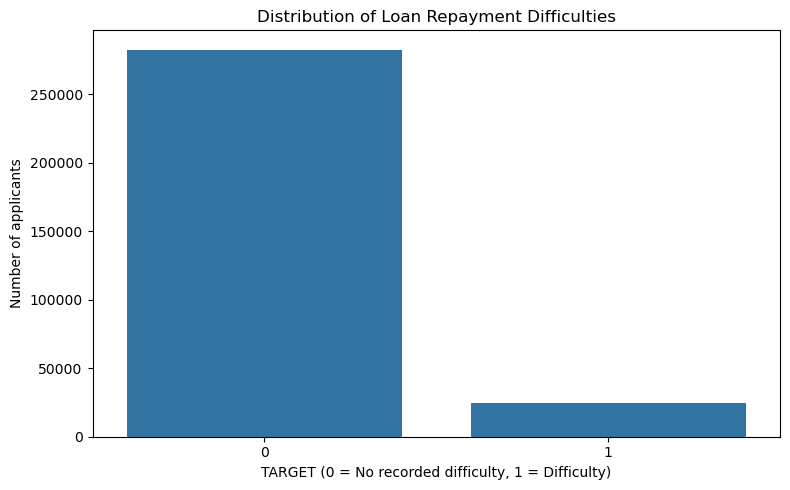

In [4]:
# Target distribution
target_counts = df["TARGET"].value_counts().sort_index()

target_percent = (df["TARGET"].value_counts(normalize=True).sort_index() * 100)

print("Target summary:")
print(pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percent.round(2)
}))

# Visualization
plt.figure(figsize=(8, 5))
c_plot = sns.countplot(data=df, x="TARGET")

c_plot.set_title("Distribution of Loan Repayment Difficulties")
c_plot.set_xlabel("TARGET (0 = No recorded difficulty, 1 = Difficulty)")
c_plot.set_ylabel("Number of applicants")
plt.tight_layout()
plt.show()

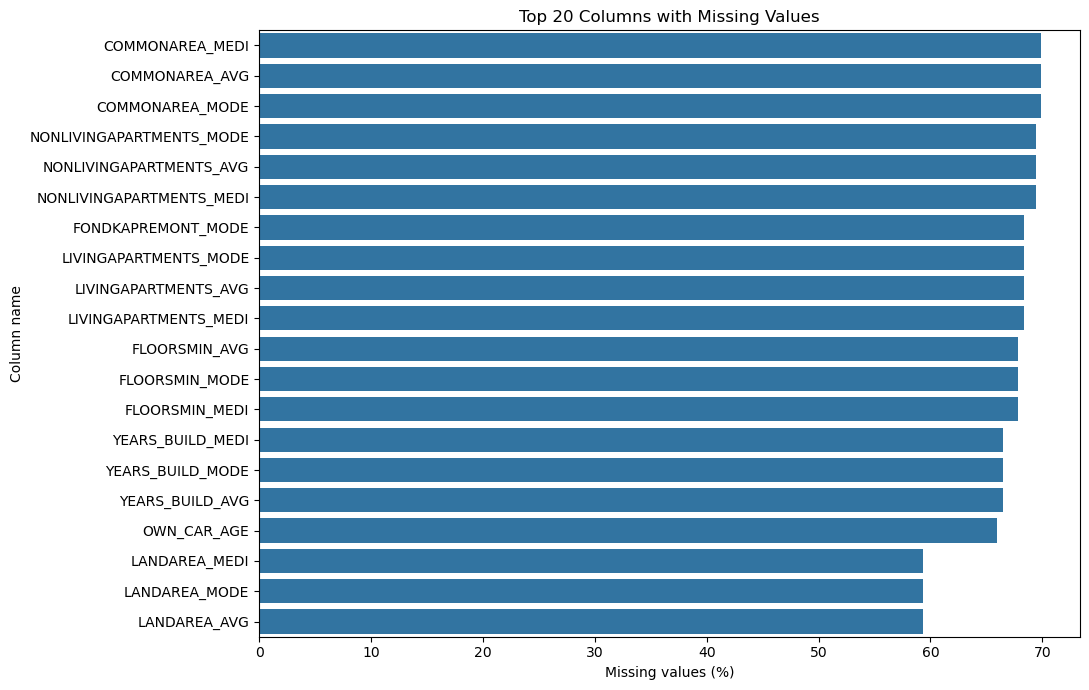

In [5]:
# Missing Value Analysis

missing_percent = (df.isnull().mean() * 100).sort_values(ascending=False)

missing_percent = missing_percent[missing_percent > 0].head(20)

plt.figure(figsize=(11, 7))
sns.barplot(
    x=missing_percent.values,
    y=missing_percent.index
)

plt.title("Top 20 Columns with Missing Values")
plt.xlabel("Missing values (%)")
plt.ylabel("Column name")
plt.tight_layout()
plt.show()

In [6]:
# Numerical Feature Analysis
numeric_cols = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED"
]

numeric_cols = [col for col in numeric_cols if col in df.columns]

df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1615.5,16524.0,24903.0,34596.0,258025.5
AMT_GOODS_PRICE,307233.0,538396.207429,369446.460540,40500.0,238500.0,450000.0,679500.0,4050000.0
DAYS_BIRTH,307511.0,-16036.995067,4363.988632,-25229.0,-19682.0,-15750.0,-12413.0,-7489.0
DAYS_EMPLOYED,307511.0,63815.045904,141275.766519,-17912.0,-2760.0,-1213.0,-289.0,365243.0


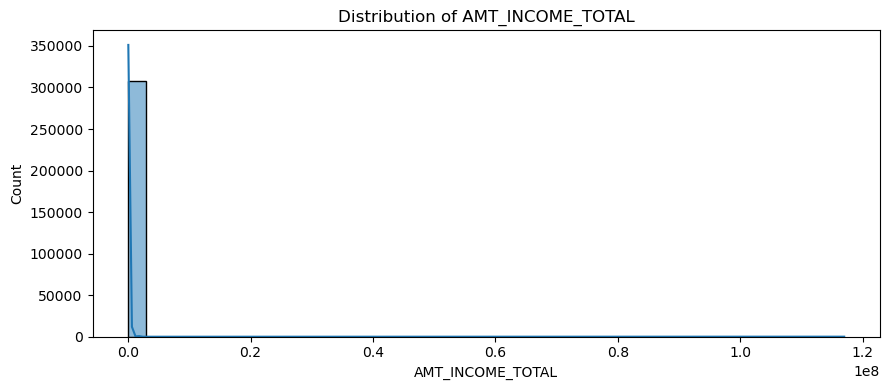

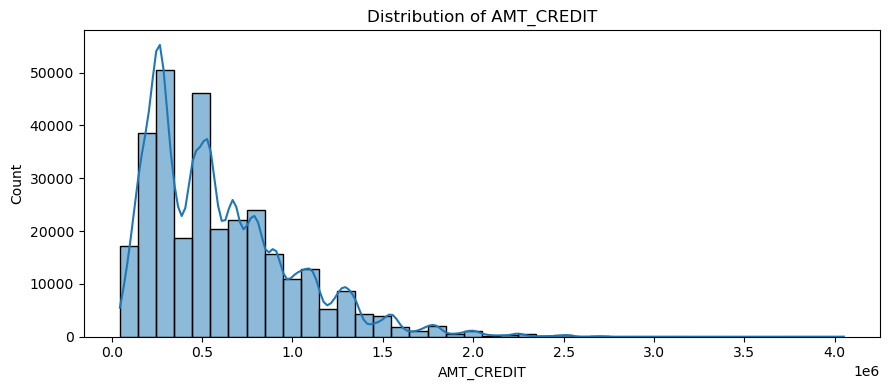

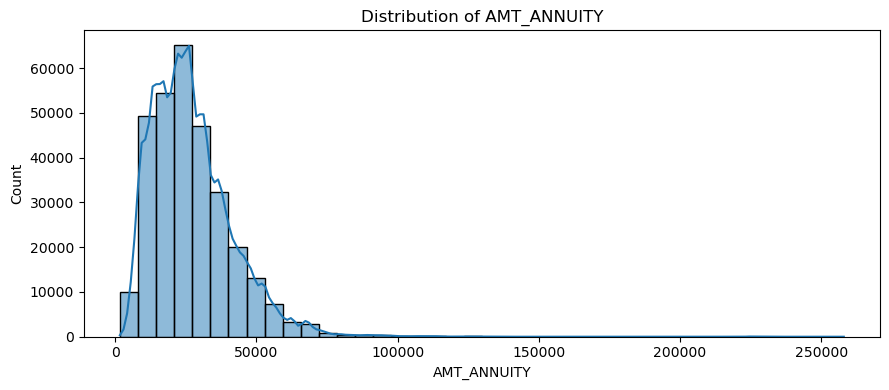

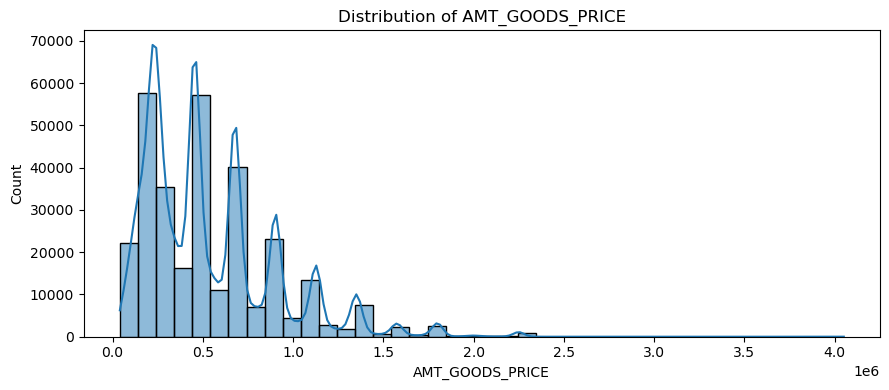

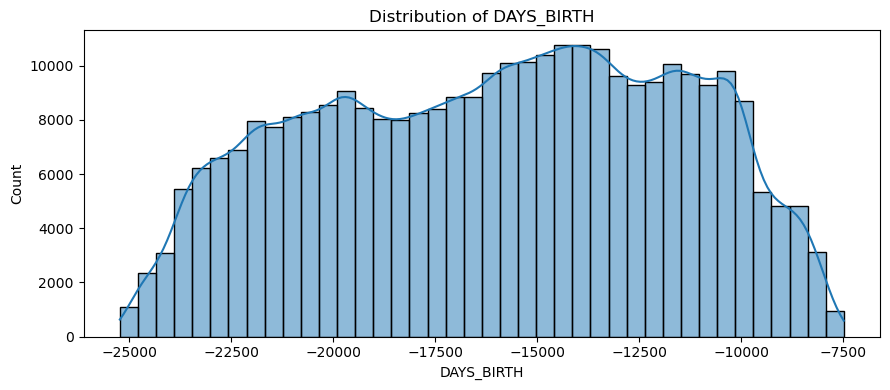

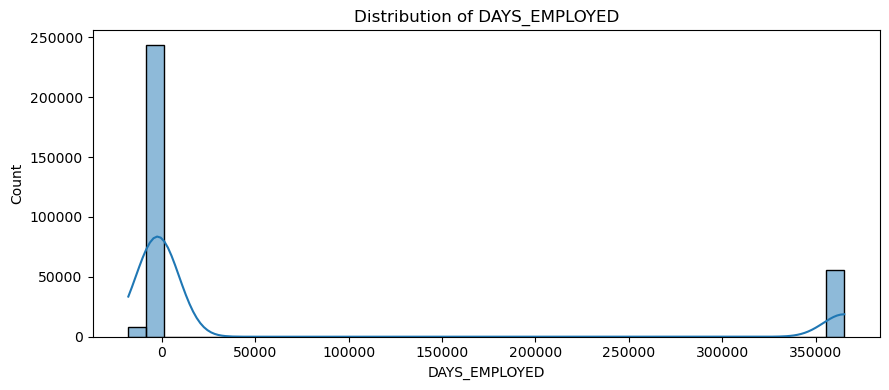

In [7]:
for col in numeric_cols:
    plt.figure(figsize=(9, 4))

    sns.histplot(
        data=df,
        x=col,
        bins=40,
        kde=True
    )

    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

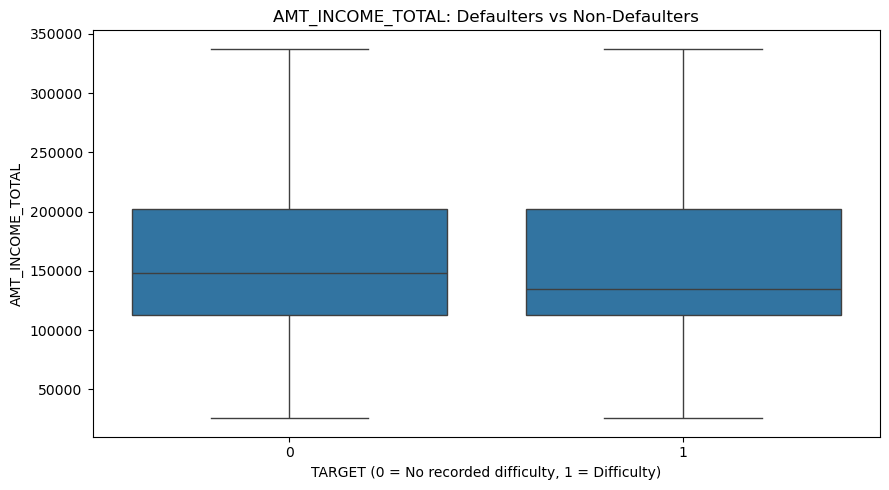

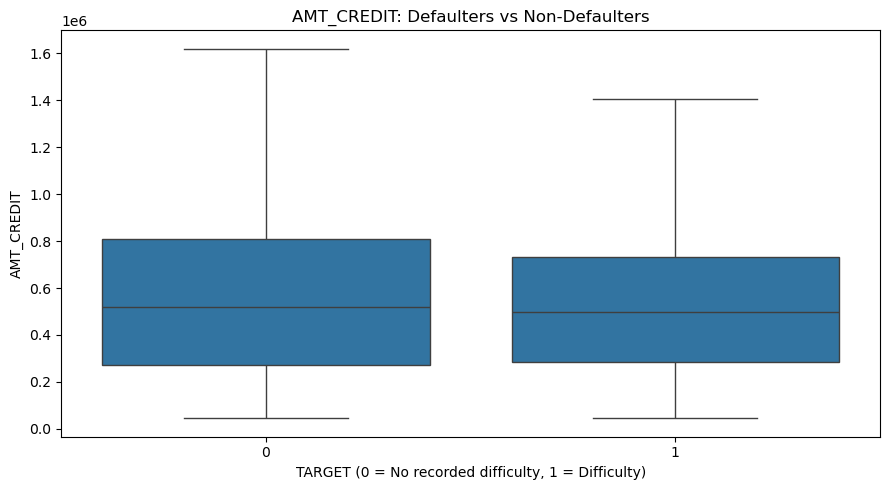

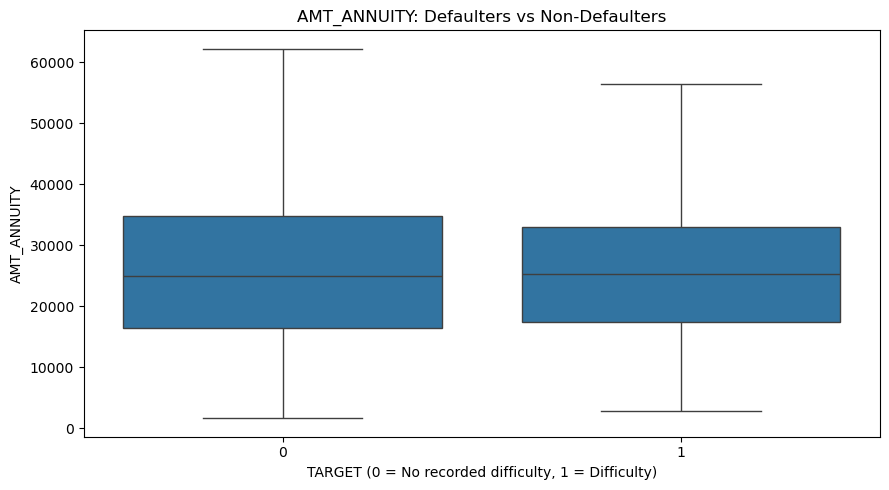

In [8]:
# Compare defaulters and non-defaulters
comparison_cols = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY"
]

for col in comparison_cols:
    if col in df.columns:
        plt.figure(figsize=(9, 5))

        sns.boxplot(
            data=df,
            x="TARGET",
            y=col,
            showfliers=False
        )

        plt.title(f"{col}: Defaulters vs Non-Defaulters")
        plt.xlabel("TARGET (0 = No recorded difficulty, 1 = Difficulty)")
        plt.ylabel(col)
        plt.tight_layout()
        plt.show()

In [9]:
# Default Rate for Each Group
for col in comparison_cols:
    if col in df.columns:
        summary = df.groupby("TARGET")[col].agg(["mean", "median"])
        
        print(f"\n{col}")
        print(summary.round(2))


AMT_INCOME_TOTAL
             mean    median
TARGET                     
0       169077.72  148500.0
1       165611.76  135000.0

AMT_CREDIT
             mean    median
TARGET                     
0       602648.28  517788.0
1       557778.53  497520.0

AMT_ANNUITY
            mean   median
TARGET                   
0       27163.62  24876.0
1       26481.74  25263.0



NAME_INCOME_TYPE
                      Applicants  Default_Rate
NAME_INCOME_TYPE                              
Pensioner                  55362          5.39
State servant              21703          5.75
Commercial associate       71617          7.48
Working                   158774          9.59


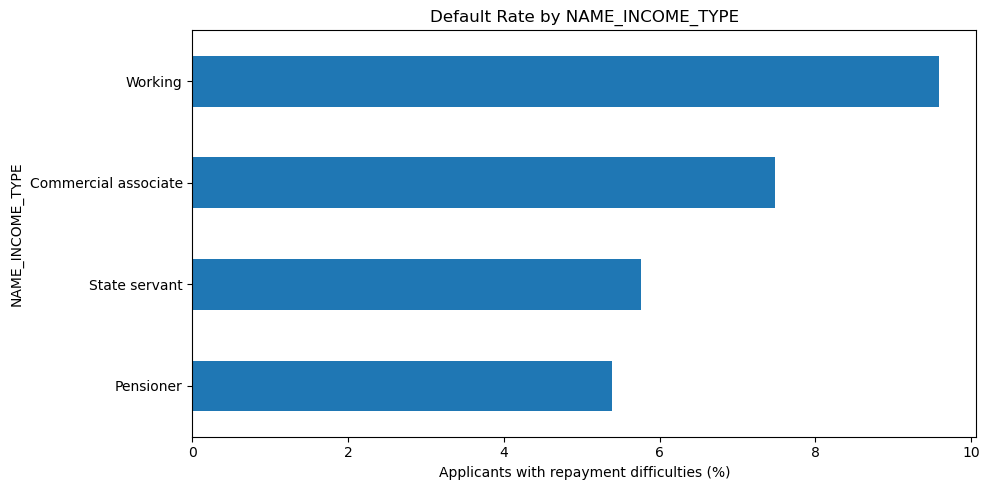


NAME_EDUCATION_TYPE
                               Applicants  Default_Rate
NAME_EDUCATION_TYPE                                    
Academic degree                       164          1.83
Higher education                    74863          5.36
Incomplete higher                   10277          8.48
Secondary / secondary special      218391          8.94
Lower secondary                      3816         10.93


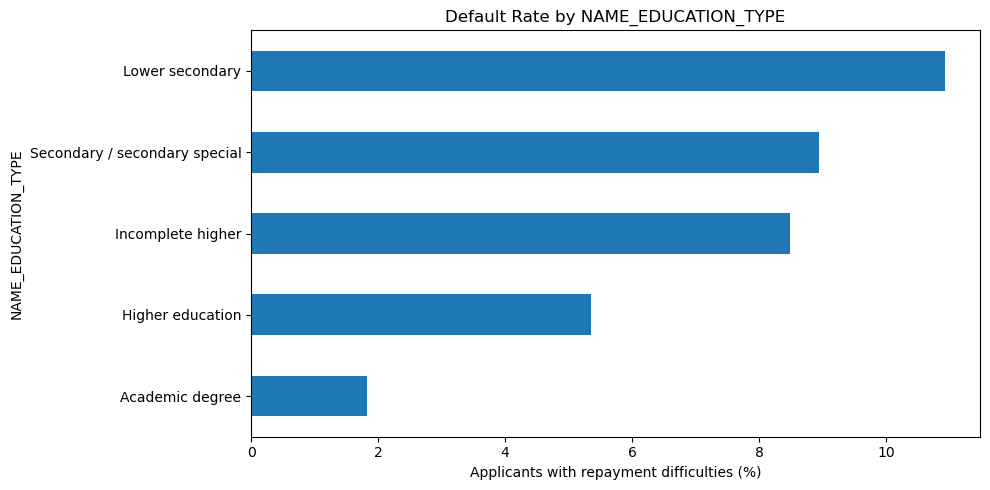


NAME_CONTRACT_TYPE
                    Applicants  Default_Rate
NAME_CONTRACT_TYPE                          
Revolving loans          29279          5.48
Cash loans              278232          8.35


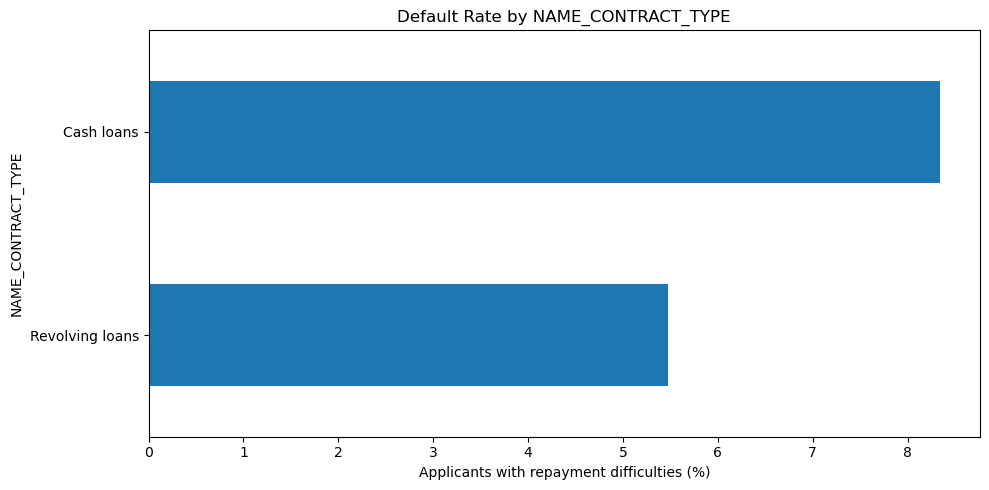


NAME_FAMILY_STATUS
                      Applicants  Default_Rate
NAME_FAMILY_STATUS                            
Widow                      16088          5.82
Married                   196432          7.56
Separated                  19770          8.19
Single / not married       45444          9.81
Civil marriage             29775          9.94


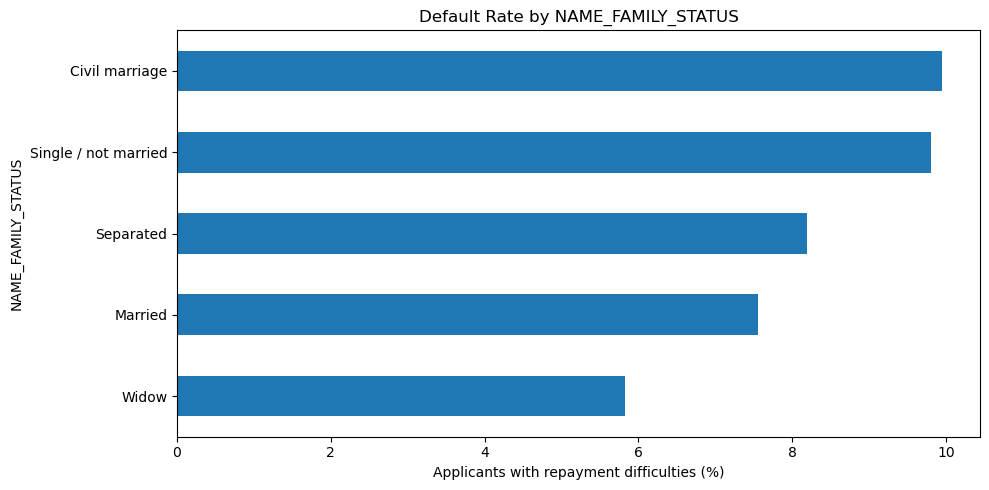


OCCUPATION_TYPE
                       Applicants  Default_Rate
OCCUPATION_TYPE                                
Accountants                  9813          4.83
High skill tech staff       11380          6.16
Managers                    21371          6.21
Core staff                  27570          6.30
HR staff                      563          6.39
IT staff                      526          6.46
NaN                         96391          6.51
Private service staff        2652          6.60
Medicine staff               8537          6.70
Secretaries                  1305          7.05
Realty agents                 751          7.86
Cleaning staff               4653          9.61
Sales staff                 32102          9.63
Cooking staff                5946         10.44
Laborers                    55186         10.58
Security staff               6721         10.74
Waiters/barmen staff         1348         11.28
Drivers                     18603         11.33
Low-skill Laborers     

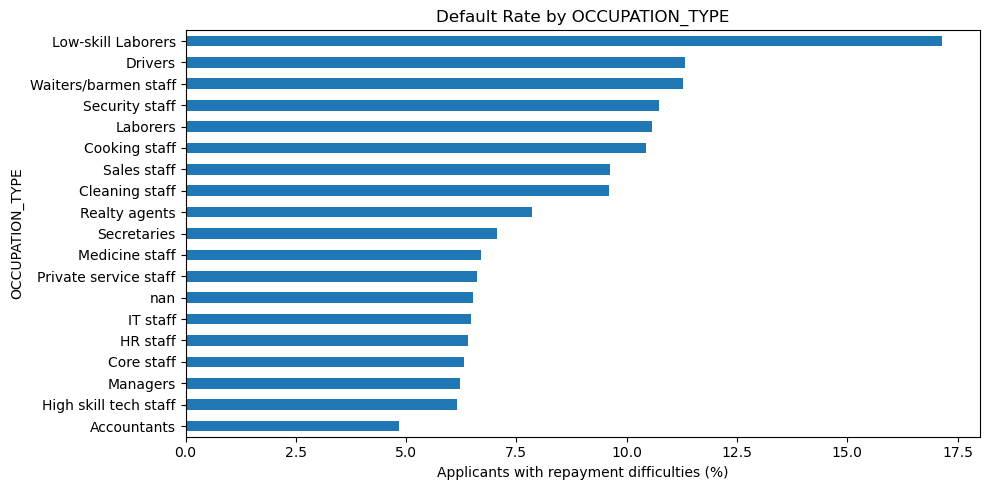

In [10]:
# Categorical Feature Analysis
categorical_cols = [
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_CONTRACT_TYPE",
    "NAME_FAMILY_STATUS",
    "OCCUPATION_TYPE"
]

for col in categorical_cols:
    if col not in df.columns:
        continue

    summary = (
        df.groupby(col, dropna=False)["TARGET"]
        .agg(Applicants="count", Default_Rate="mean")
    )

    # Display rates as percentages
    summary["Default_Rate"] *= 100

    # Avoid drawing conclusions from very small groups
    summary = summary[summary["Applicants"] >= 100]
    summary = summary.sort_values("Default_Rate")

    print(f"\n{col}")
    print(summary.round(2))

    plt.figure(figsize=(10, 5))
    summary["Default_Rate"].plot(kind="barh")

    plt.title(f"Default Rate by {col}")
    plt.xlabel("Applicants with repayment difficulties (%)")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

           Applicants  Default_Rate
AGE_GROUP                          
[0, 25)         12233         12.29
[25, 35)        72429         10.66
[35, 45)        84261          8.41
[45, 55)        70190          7.05
[55, 65)        60522          5.42
[65, 100)        7876          3.66


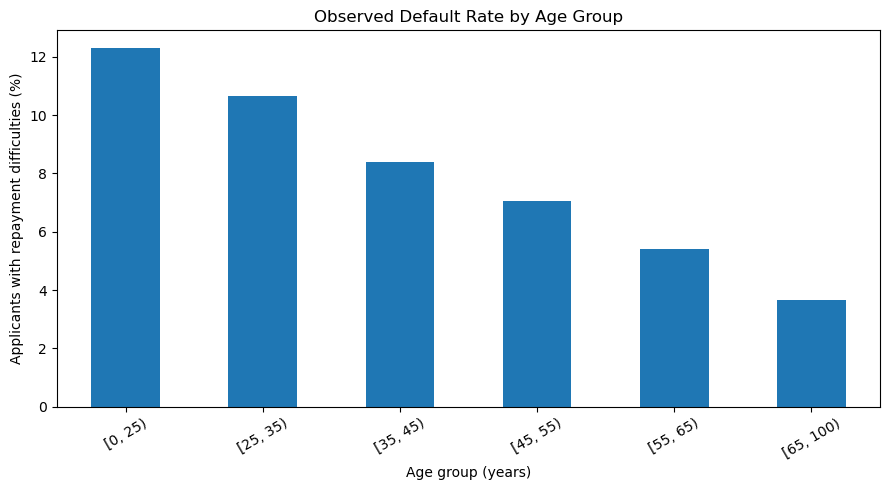

In [11]:
# Defaulter vs Non-Defaulter Analysis
df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365.25

# Summary by age group
df["AGE_GROUP"] = pd.cut(
    df["AGE_YEARS"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    right=False
)

age_summary = df.groupby(
    "AGE_GROUP", observed=False
).agg(
    Applicants=("TARGET", "size"),
    Default_Rate=("TARGET", "mean")
)

age_summary["Default_Rate"] *= 100

print(age_summary.round(2))

plt.figure(figsize=(9, 5))
age_summary["Default_Rate"].plot(kind="bar")

plt.title("Observed Default Rate by Age Group")
plt.xlabel("Age group (years)")
plt.ylabel("Applicants with repayment difficulties (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

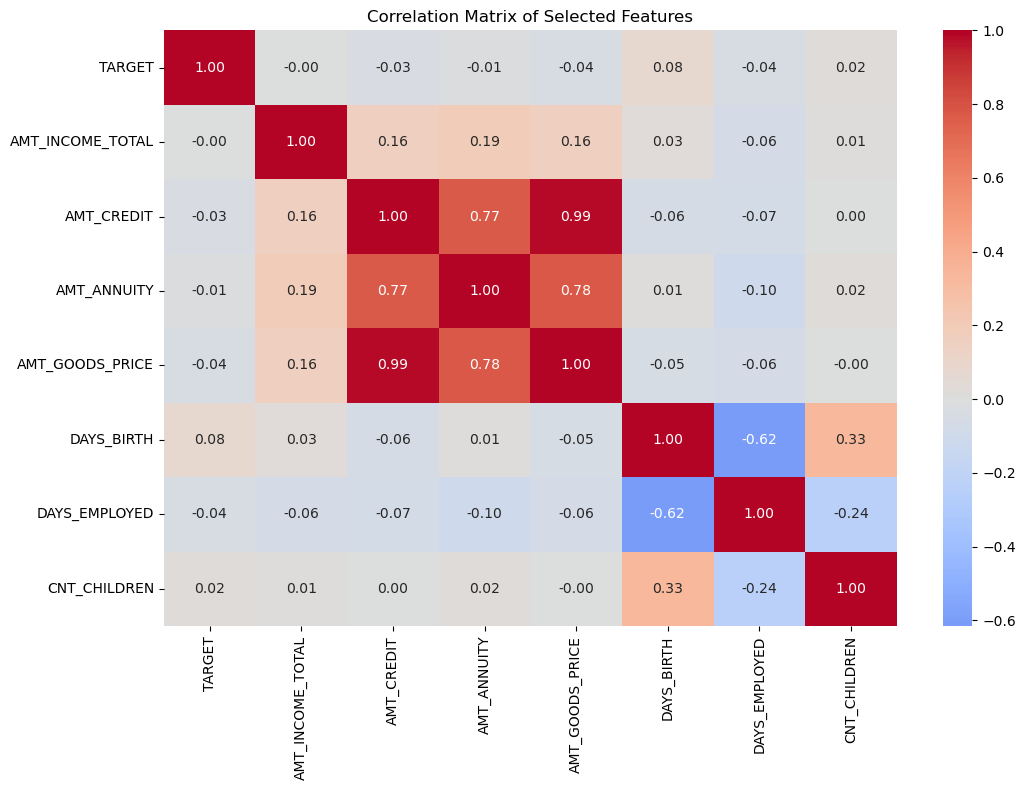

In [12]:
# Correlation Analysis
corr_cols = [
    "TARGET",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "CNT_CHILDREN"
]

corr_cols = [c for c in corr_cols if c in df.columns]

correlation = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Matrix of Selected Features")
plt.tight_layout()
plt.show()

## Exploratory Data Analysis (EDA) – Key Findings

### 1. Dataset Overview
The dataset contains 307,511 loan applications and 122 input features, excluding the target variable and applicant ID.

### 2. Target Variable Analysis
The target variable is imbalanced:
- 91.93% of applicants have TARGET = 0 (no recorded repayment difficulties).
- 8.07% of applicants have TARGET = 1 (repayment difficulties).

Therefore, accuracy alone is not sufficient to evaluate the predictive models.

### 3. Missing Values
The dataset contains missing values in several columns. Missing values are handled using numerical and categorical imputation techniques in the preprocessing pipeline.

### 4. Applicant Income Analysis
Applicants with and without recorded repayment difficulties show differences in their income distributions. Income may help the model identify patterns associated with repayment risk.

### 5. Age Group Analysis
The repayment-difficulty rate varies across age groups. This indicates that age may be useful for understanding patterns in the dataset.

### 6. Correlation Analysis
Correlation analysis helps identify relationships between numerical features. Correlation does not necessarily mean that one variable causes another.

### 7. EDA Conclusion
The analysis identifies class imbalance, missing values and differences across applicant groups. These findings help guide data preprocessing and machine-learning model development.

In [13]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["TARGET", "SK_ID_CURR"], errors="ignore")
y = df["TARGET"]

print("Feature shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

Feature shape: (307511, 122)

Target distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Target percentage:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


In [14]:
# Split the dataset 80% and 20%
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Training records: 246008
Testing records: 61503


In [15]:
# Handle missing values and categorical features
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Numerical columns:", len(numeric_features))
print("Categorical columns:", len(categorical_features))


Numerical columns: 105
Categorical columns: 17


In [16]:
# Import machine-learning libraries

import time
import warnings
warnings.filterwarnings('ignore')
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

In [17]:
# Train multiple machine-learning models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        solver="saga",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        min_samples_leaf=100,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=50,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=50,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    )
}
print(list(models))

['Logistic Regression', 'Decision Tree', 'Random Forest', 'Extra Trees']


In [18]:
import time

start_time = time.time()

trained_models = {}

pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=200,
        solver="saga",
        class_weight="balanced",
        random_state=42
    ))
])

print("Starting Logistic Regression training...", flush=True)

pipeline.fit(X_train, y_train)

trained_models["Logistic Regression"] = pipeline

print("Training completed!")
print("Time taken:", round(time.time() - start_time, 2), "seconds")


Starting Logistic Regression training...
Training completed!
Time taken: 190.05 seconds


In [19]:
# Make predictions using the trained model
y_pred = pipeline.predict(X_test)
y_prob = pipeline.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Logistic Regression Model Performance")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

Logistic Regression Model Performance
----------------------------------------
Accuracy: 0.6893
Precision: 0.1613
Recall: 0.6785
F1 Score: 0.2607
PR-AUC: 0.2278
ROC-AUC: 0.7491


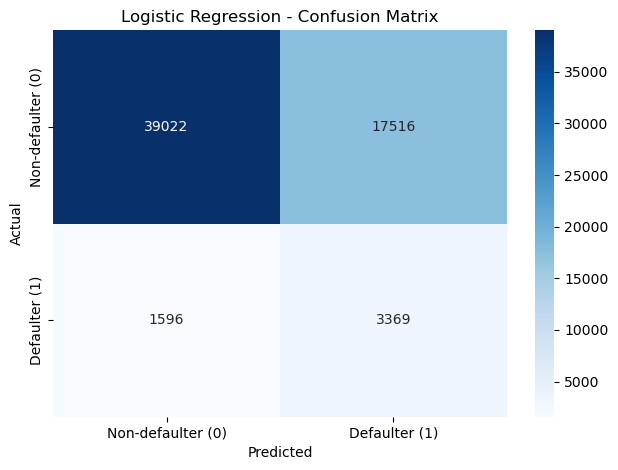

               precision    recall  f1-score   support

Non-defaulter       0.96      0.69      0.80     56538
    Defaulter       0.16      0.68      0.26      4965

     accuracy                           0.69     61503
    macro avg       0.56      0.68      0.53     61503
 weighted avg       0.90      0.69      0.76     61503



In [20]:
# Display the confusion matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-defaulter (0)", "Defaulter (1)"],
    yticklabels=["Non-defaulter (0)", "Defaulter (1)"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-defaulter", "Defaulter"],
    zero_division=0
))


In [21]:
# Train the Decision Tree model
start_time = time.time()

dt_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=100,
        class_weight="balanced",
        random_state=42
    ))
])

print("Training Decision Tree...", flush=True)

dt_pipeline.fit(X_train, y_train)

print("Decision Tree training completed!")
print("Time taken:", round(time.time() - start_time, 2), "seconds")

Training Decision Tree...
Decision Tree training completed!
Time taken: 40.82 seconds


In [22]:
# Evaluate Decision Tree

dt_pred = dt_pipeline.predict(X_test)
dt_prob = dt_pipeline.predict_proba(X_test)[:, 1]

dt_results = {
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_test, dt_pred),
    "Precision": precision_score(y_test, dt_pred, zero_division=0),
    "Recall": recall_score(y_test, dt_pred, zero_division=0),
    "F1 Score": f1_score(y_test, dt_pred, zero_division=0),
    "PR-AUC": average_precision_score(y_test, dt_prob),
    "ROC-AUC": roc_auc_score(y_test, dt_prob)
}

print(pd.DataFrame([dt_results]).round(4).to_string(index=False))


        Model  Accuracy  Precision  Recall  F1 Score  PR-AUC  ROC-AUC
Decision Tree    0.6695     0.1476  0.6481    0.2405  0.1961   0.7107


In [23]:
# compare Logistic Regression and Decision Tree

# Evaluate Logistic Regression again without retraining
lr_pred = pipeline.predict(X_test)
lr_prob = pipeline.predict_proba(X_test)[:, 1]

lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, lr_pred),
    "Precision": precision_score(y_test, lr_pred, zero_division=0),
    "Recall": recall_score(y_test, lr_pred, zero_division=0),
    "F1 Score": f1_score(y_test, lr_pred, zero_division=0),
    "PR-AUC": average_precision_score(y_test, lr_prob),
    "ROC-AUC": roc_auc_score(y_test, lr_prob)
}

comparison_df = pd.DataFrame([lr_results, dt_results])
print(comparison_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score  PR-AUC  ROC-AUC
Logistic Regression    0.6893     0.1613  0.6785    0.2607  0.2278   0.7491
      Decision Tree    0.6695     0.1476  0.6481    0.2405  0.1961   0.7107


In [24]:
# Train the Random Forest model
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
import time

start_time = time.time()

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=100,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ))
])

print("Training Random Forest...", flush=True)

rf_pipeline.fit(X_train, y_train)

print("Random Forest training completed!")
print("Time taken:", round(time.time() - start_time, 2), "seconds")


Training Random Forest...
Random Forest training completed!
Time taken: 35.04 seconds


In [25]:
# Evaluate Random Forest

rf_pred = rf_pipeline.predict(X_test)
rf_prob = rf_pipeline.predict_proba(X_test)[:, 1]

rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred, zero_division=0),
    "Recall": recall_score(y_test, rf_pred, zero_division=0),
    "F1 Score": f1_score(y_test, rf_pred, zero_division=0),
    "PR-AUC": average_precision_score(y_test, rf_prob),
    "ROC-AUC": roc_auc_score(y_test, rf_prob)
}

print(pd.DataFrame([rf_results]).round(4).to_string(index=False))

        Model  Accuracy  Precision  Recall  F1 Score  PR-AUC  ROC-AUC
Random Forest    0.7337      0.172   0.603    0.2677  0.2152   0.7397


In [26]:
# Compare all three models

comparison_df = pd.DataFrame([
    lr_results,
    dt_results,
    rf_results
])

comparison_df = comparison_df.sort_values(
    by="PR-AUC",
    ascending=False
)

print(comparison_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score  PR-AUC  ROC-AUC
Logistic Regression    0.6893     0.1613  0.6785    0.2607  0.2278   0.7491
      Random Forest    0.7337     0.1720  0.6030    0.2677  0.2152   0.7397
      Decision Tree    0.6695     0.1476  0.6481    0.2405  0.1961   0.7107


In [27]:
# Extra Trees Classifier

start_time = time.time()

et_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", ExtraTreesClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=100,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ))
])

print("Training Extra Trees...", flush=True)

et_pipeline.fit(X_train, y_train)

print("Extra Trees training completed!")
print("Time taken:", round(time.time() - start_time, 2), "seconds")

Training Extra Trees...
Extra Trees training completed!
Time taken: 41.32 seconds


In [28]:
# Evaluate Extra Trees

et_pred = et_pipeline.predict(X_test)
et_prob = et_pipeline.predict_proba(X_test)[:, 1]

et_results = {
    "Model": "Extra Trees",
    "Accuracy": accuracy_score(y_test, et_pred),
    "Precision": precision_score(
        y_test, et_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, et_pred, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, et_pred, zero_division=0
    ),
    "PR-AUC": average_precision_score(y_test, et_prob),
    "ROC-AUC": roc_auc_score(y_test, et_prob)
}

print(pd.DataFrame([et_results]).round(4).to_string(index=False))


      Model  Accuracy  Precision  Recall  F1 Score  PR-AUC  ROC-AUC
Extra Trees    0.6791     0.1514  0.6463    0.2454   0.201   0.7236


In [29]:
# Compare all four models
comparison_df = pd.DataFrame([
    lr_results,
    dt_results,
    rf_results,
    et_results
])

comparison_df = comparison_df.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

print(comparison_df.round(4).to_string(index=False))


              Model  Accuracy  Precision  Recall  F1 Score  PR-AUC  ROC-AUC
Logistic Regression    0.6893     0.1613  0.6785    0.2607  0.2278   0.7491
      Random Forest    0.7337     0.1720  0.6030    0.2677  0.2152   0.7397
        Extra Trees    0.6791     0.1514  0.6463    0.2454  0.2010   0.7236
      Decision Tree    0.6695     0.1476  0.6481    0.2405  0.1961   0.7107


# Visualize model performance

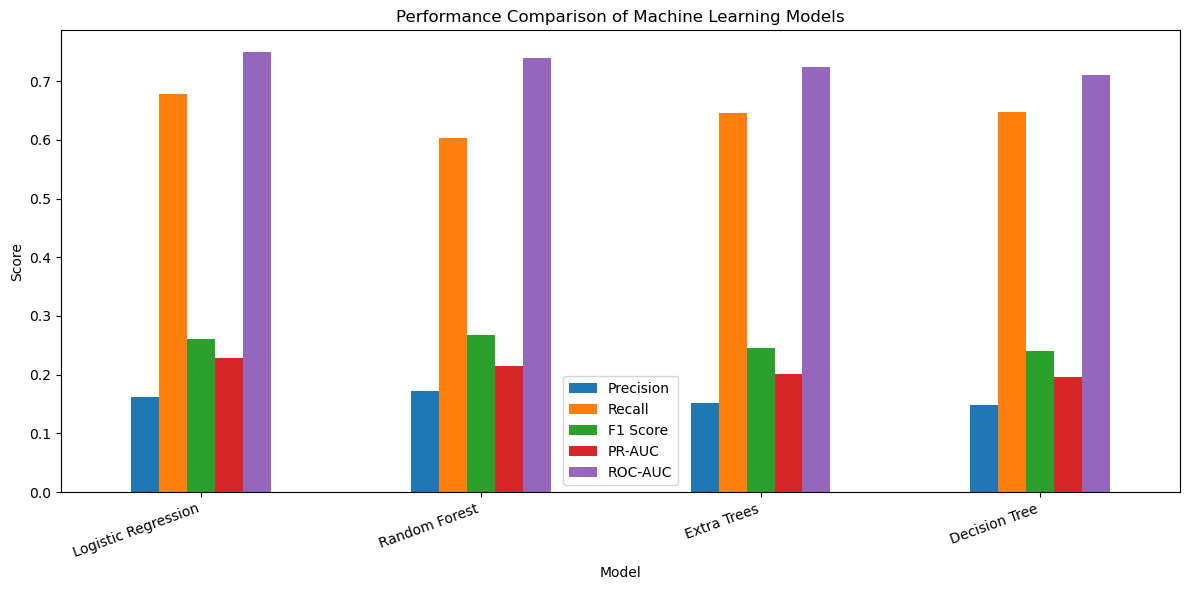

In [30]:
metrics = ["Precision", "Recall", "F1 Score", "PR-AUC", "ROC-AUC"]

comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="best")
plt.tight_layout()
plt.show()


# Identify important features

                                               Feature  Importance
                                     num__EXT_SOURCE_3    0.173030
                                     num__EXT_SOURCE_2    0.148556
                                     num__EXT_SOURCE_1    0.054116
                                    num__DAYS_EMPLOYED    0.038359
                                        num__AGE_YEARS    0.032396
                                       num__DAYS_BIRTH    0.029901
                                  num__AMT_GOODS_PRICE    0.025988
                           num__DAYS_LAST_PHONE_CHANGE    0.025186
                                       num__AMT_CREDIT    0.022917
                                  num__DAYS_ID_PUBLISH    0.020033
             cat__NAME_EDUCATION_TYPE_Higher education    0.019926
                                      num__AMT_ANNUITY    0.018279
                                num__DAYS_REGISTRATION    0.014456
cat__NAME_EDUCATION_TYPE_Secondary / secondary special    0.01

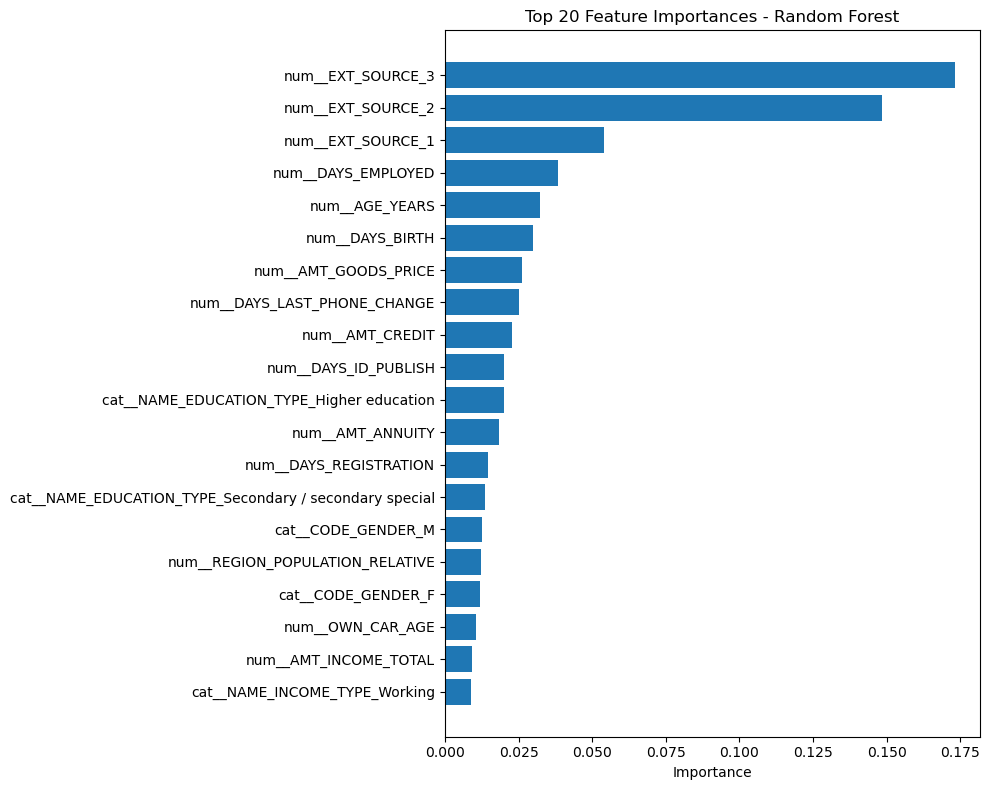

In [31]:
# Get feature names after preprocessing
feature_names = rf_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get Random Forest feature importance
importances = rf_pipeline.named_steps[
    "model"
].feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

# Display top 20 features
print(feature_importance_df.head(20).to_string(index=False))

# Plot top 20 features
top_features = feature_importance_df.head(20).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 8))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 20 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [32]:
# candidate model
import joblib

joblib.dump(rf_pipeline, "home_loan_default_model.pkl")

print("Model saved successfully!")

Model saved successfully!


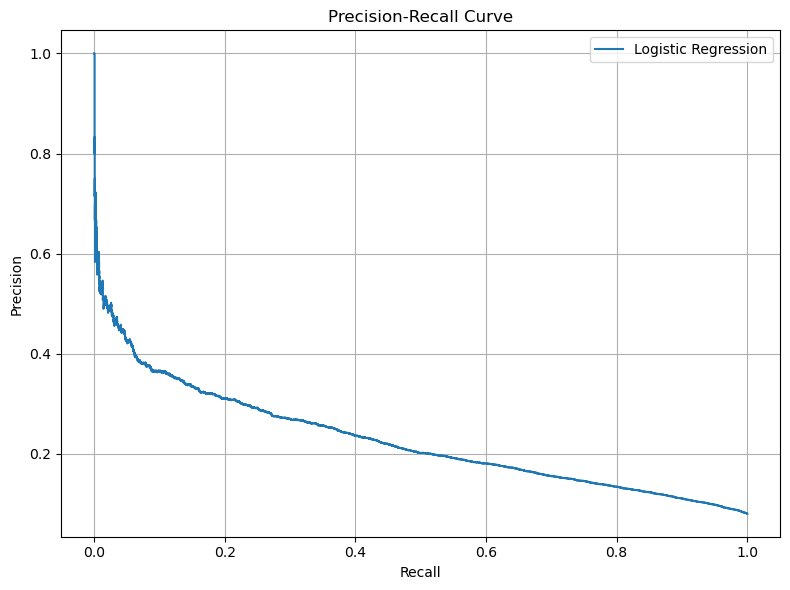

In [33]:
# Precision-Recall curve

from sklearn.metrics import precision_recall_curve

# Probabilities from the trained Logistic Regression model
lr_prob = pipeline.predict_proba(X_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_test, lr_prob
)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label="Logistic Regression")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [34]:
# decision threshold
lr_prob = pipeline.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):
    pred = (lr_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1 Score
      0.10     0.0820  0.9982    0.1515
      0.15     0.0853  0.9905    0.1570
      0.20     0.0907  0.9738    0.1659
      0.25     0.0982  0.9521    0.1781
      0.30     0.1075  0.9138    0.1923
      0.35     0.1188  0.8711    0.2090
      0.40     0.1310  0.8125    0.2256
      0.45     0.1457  0.7515    0.2440
      0.50     0.1613  0.6785    0.2607
      0.55     0.1810  0.6012    0.2782
      0.60     0.2007  0.5116    0.2883
      0.65     0.2283  0.4286    0.2979
      0.70     0.2592  0.3416    0.2948
      0.75     0.2922  0.2491    0.2690
      0.80     0.3303  0.1559    0.2118
      0.85     0.3763  0.0818    0.1343
      0.90     0.4808  0.0278    0.0526


### Model Comparison and Selection

Four machine-learning algorithms were evaluated for the Home Loan Default Prediction project: Logistic Regression, Decision Tree, Random Forest, and Extra Trees.

Logistic Regression achieved the highest PR-AUC of 0.2278 and the highest recall of 67.85%. Random Forest achieved the highest accuracy of 73.37% and F1-score of 0.2677.

Based on the current evaluation, Logistic Regression is the leading candidate because it achieved the best PR-AUC and recall. However, its precision of 16.13% indicates a substantial number of false-positive predictions.

Before production deployment, the model requires further validation, decision-threshold selection, calibration assessment, and evaluation of business costs and potential fairness risks.

### Model Comparison and Selection

Four machine-learning algorithms were evaluated for the Home Loan Default Prediction project: Logistic Regression, Decision Tree, Random Forest, and Extra Trees.

Logistic Regression achieved the highest PR-AUC of 0.2278 and the highest recall of 67.85%. Random Forest achieved the highest accuracy of 73.37% and F1-score of 0.2677.

Based on the current evaluation, Logistic Regression is the leading candidate because it achieved the best PR-AUC and recall. However, its precision of 16.13% indicates a substantial number of false-positive predictions.

Before production deployment, the model requires further validation, decision-threshold selection, calibration assessment, and evaluation of business costs and potential fairness risks.

# final prediction report

Classification Report at Threshold: 0.5
               precision    recall  f1-score   support

Non-defaulter       0.96      0.69      0.80     56538
    Defaulter       0.16      0.68      0.26      4965

     accuracy                           0.69     61503
    macro avg       0.56      0.68      0.53     61503
 weighted avg       0.90      0.69      0.76     61503



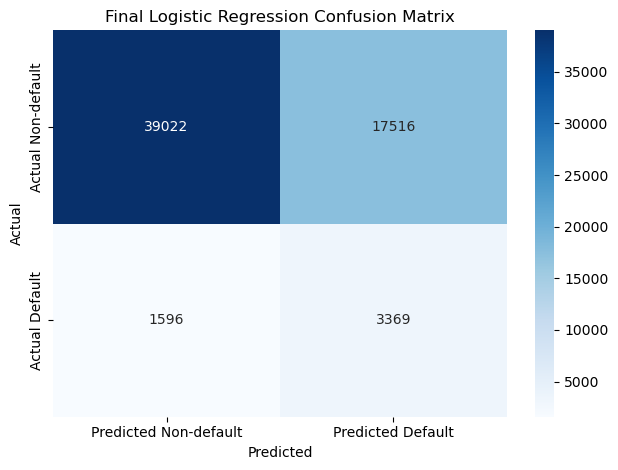

In [35]:
# Baseline threshold
threshold = 0.50

lr_prob = pipeline.predict_proba(X_test)[:, 1]
final_pred = (lr_prob >= threshold).astype(int)

print("Classification Report at Threshold:", threshold)
print(classification_report(
    y_test,
    final_pred,
    target_names=["Non-defaulter", "Defaulter"],
    zero_division=0
))

cm = confusion_matrix(y_test, final_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Non-default", "Predicted Default"],
    yticklabels=["Actual Non-default", "Actual Default"]
)

plt.title("Final Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [36]:
joblib.dump(
    pipeline,
    "home_loan_default_logistic_regression.pkl"
)

print("Logistic Regression model saved successfully.")

Logistic Regression model saved successfully.


### Final Model Evaluation and Conclusion

Four classification models were evaluated for the Home Loan Default Prediction project. Logistic Regression achieved the highest PR-AUC of 0.2278 and recall of 67.85%, while Random Forest achieved the highest accuracy of 73.37%.

The threshold analysis demonstrated a trade-off between precision and recall. At a threshold of 0.50, Logistic Regression achieved precision of 16.13%, recall of 67.85%, and an F1-score of 0.2607. At a threshold of 0.60, precision increased to 20.07% and the F1-score increased to 0.2883, but recall decreased to 51.16%.

Logistic Regression is the leading candidate based on the current results. Before production deployment, further validation is required, including threshold selection on validation data, probability calibration, fairness assessment, and evaluation of the financial consequences of false-positive and false-negative predictions.